<a href="https://colab.research.google.com/github/laboratoriodecodigos/Colab-Python/blob/main/Visitors_con_YOLO_WORLD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!nvidia-smi

Tue Nov 10 16:52:29 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

##Install required packages

In [1]:
!pip install -U supervision

  Using cached supervision-0.31.6-py3-none-any.whl.metadata (14 kB)
Using cached supervision-0.31.6-py3-none-any.whl (498 kB)
  Attempting uninstall: supervision
    Found existing installation: supervision 0.30.9
    Uninstalling supervision-0.30.9:
      Successfully uninstalled supervision-0.30.9
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
inference-gpu 1.8.4 requires supervision<0.31.0,>=0.26, but you have supervision 0.31.6 which is incompatible.
inference-gpu 1.8.4 requires supervision<0.31.0,>=0.30.6, but you have supervision 0.31.6 which is incompatible.
streamvision 0.1.5 requires supervision<0.31.0,>=0.30.6, but you have supervision 0.31.6 which is incompatible.
inference-sdk 1.8.4 requires supervision<0.31.0,>=0.26, but you have supervision 0.31.6 which is incompatible.
roboflow-workflows 0.2.15 requires supervision<0.31.0,>=0.30.6, but you have 

In [3]:
!pip install -q inference-gpu[yolo-world]

In [7]:
!pip install dill

##Imports

In [4]:
import cv2
import supervision as sv

from tqdm import tqdm
from inference.models.yolo_world.yolo_world import YOLOWorld

/usr/local/lib/python3.13/dist-packages/inference/core/env.py:345: InferenceDeprecationWarning: CORE_MODEL_GAZE_ENABLED is True: POST /gaze/gaze_detection is registered as a deprecation stub returning HTTP 410 Gone. The stub and this flag will be removed end of Q2 2026. Set CORE_MODEL_GAZE_ENABLED=False to disable it now.
  warnings.warn(


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/tmp/roboflow-inference/ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


/usr/local/lib/python3.13/dist-packages/pydantic/_internal/_fields.py:198: UserWarning: Field name "schema" in "WorkflowsBlocksSchemaDescription" shadows an attribute in parent "BaseModel"
  warnings.warn(


##Download example data

In [23]:
!wget -P '/content/' https://storage.googleapis.com/adonaivera_certified/test.jpeg
!wget -P '/content/' https://storage.googleapis.com/adonaivera_certified/test_demo1.mp4

--2026-11-10 17:00:49--  https://storage.googleapis.com/adonaivera_certified/test.jpeg
Resolving storage.googleapis.com (storage.googleapis.com)... 108.177.119.207, 108.177.127.207, 172.253.153.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|108.177.119.207|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1446640 (1.4M) [image/jpeg]
Saving to: ‘/content/test.jpeg.1’

test.jpeg.1         100%[===================>]   1.38M  2.39MB/s    in 0.6s    

2026-11-10 17:00:51 (2.39 MB/s) - ‘/content/test.jpeg.1’ saved [1446640/1446640]

--2026-11-10 17:00:51--  https://storage.googleapis.com/adonaivera_certified/test_demo1.mp4
Resolving storage.googleapis.com (storage.googleapis.com)... 108.177.119.207, 108.177.127.207, 172.253.153.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|108.177.119.207|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 43171071 (41M) [video/mp4]
Saving to: ‘/content/test_demo1.

In [30]:
SOURCE_IMAGE_PATH = f"/content/test.jpeg"
SOURCE_VIDEO_PATH = f"/content/test_demo1.mp4"

##Run Object Detection

In [9]:
model = YOLOWorld(model_id="yolo_world/l")

Creating inference sessions


/usr/local/lib/python3.13/dist-packages/onnxruntime/capi/onnxruntime_inference_collection.py:118: UserWarning: Specified provider 'OpenVINOExecutionProvider' is not in available provider names.Available providers: 'TensorrtExecutionProvider, CUDAExecutionProvider, CPUExecutionProvider'
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/onnxruntime/capi/onnxruntime_inference_collection.py:118: UserWarning: Specified provider 'CoreMLExecutionProvider' is not in available provider names.Available providers: 'TensorrtExecutionProvider, CUDAExecutionProvider, CPUExecutionProvider'
  warnings.warn(


CLIP model loaded in 20.85 seconds


In [38]:
classes = ["person"]
model.set_classes(classes)

In [39]:
image = cv2.imread(SOURCE_IMAGE_PATH)
results = model.infer(image, confidence=0.003)
detections = sv.Detections.from_inference(results).with_nms(threshold=0.1)

In [40]:
detections = sv.Detections.from_inference(results).with_nms(threshold=0.1)

In [41]:
BOUNDING_BOX_ANNOTATOR = sv.BoxAnnotator(thickness=2)
LABEL_ANNOTATOR = sv.LabelAnnotator(text_thickness=2, text_scale=1, text_color=sv.Color.BLACK)

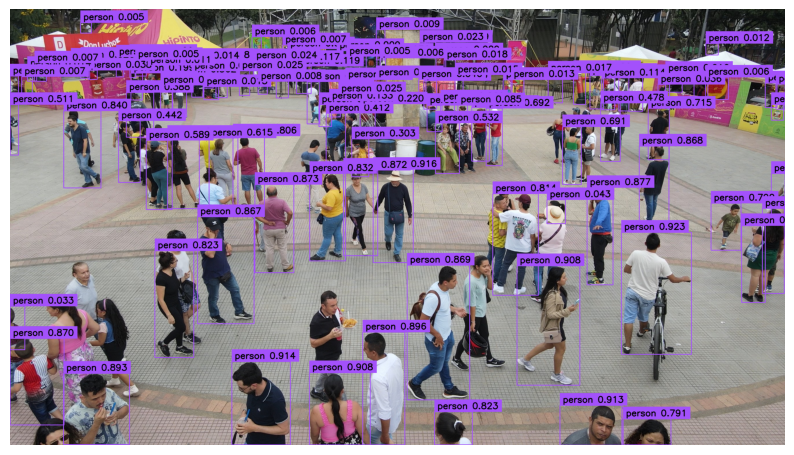

In [42]:
labels = [
    f"{classes[class_id]} {confidence:0.3f}"
    for class_id, confidence
    in zip(detections.class_id, detections.confidence)
]

image = cv2.imread(SOURCE_IMAGE_PATH)
annotated_image = image.copy()
annotated_image = BOUNDING_BOX_ANNOTATOR.annotate(annotated_image, detections)
annotated_image = LABEL_ANNOTATOR.annotate(annotated_image, detections, labels=labels)
sv.plot_image(annotated_image, (10, 10))

##Make Special Search

In [ ]:
model = YOLOWorld(model_id="yolo_world/l")

In [43]:
classes = ["person", "backpack", "persons with backpack", "persons with hats", "hats"]
model.set_classes(classes)

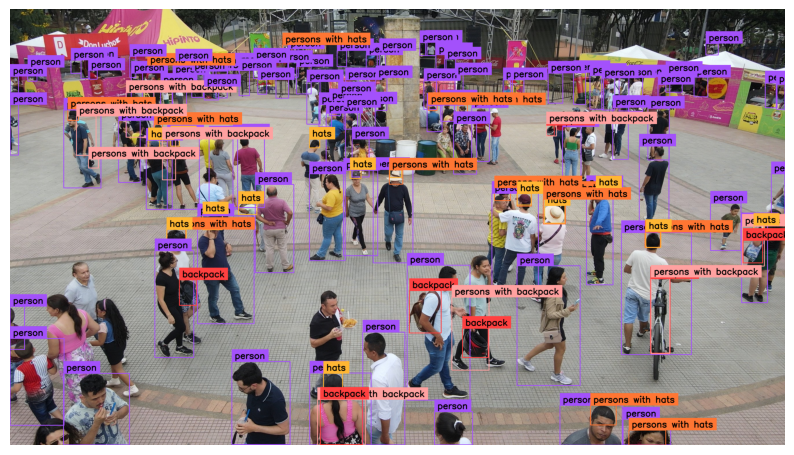

In [44]:
image = cv2.imread(SOURCE_IMAGE_PATH)
results = model.infer(image, confidence=0.003)
detections = sv.Detections.from_inference(results).with_nms(threshold=0.1)

BOUNDING_BOX_ANNOTATOR = sv.BoxAnnotator(thickness=2)
LABEL_ANNOTATOR = sv.LabelAnnotator(text_thickness=2, text_scale=1, text_color=sv.Color.BLACK)

labels = [
    f"{classes[class_id]} {confidence:0.3f}"
    for class_id, confidence
    in zip(detections.class_id, detections.confidence)
]

annotated_image = image.copy()
annotated_image = BOUNDING_BOX_ANNOTATOR.annotate(annotated_image, detections)
annotated_image = LABEL_ANNOTATOR.annotate(annotated_image, detections)
sv.plot_image(annotated_image, (10, 10))



##Saving Detections

In [45]:
csv_sink = sv.CSVSink('detections.csv')
csv_sink.open()

image = cv2.imread(SOURCE_IMAGE_PATH)
results = model.infer(image, confidence=0.003)
detections = sv.Detections.from_inference(results).with_nms(threshold=0.1)

BOUNDING_BOX_ANNOTATOR = sv.BoxAnnotator(thickness=2)
LABEL_ANNOTATOR = sv.LabelAnnotator(text_thickness=2, text_scale=1, text_color=sv.Color.BLACK)

labels = [
    f"{classes[class_id]} {confidence:0.3f}"
    for class_id, confidence
    in zip(detections.class_id, detections.confidence)
]


In [46]:
annotated_image = image.copy()
annotated_image = BOUNDING_BOX_ANNOTATOR.annotate(annotated_image, detections)
annotated_image = LABEL_ANNOTATOR.annotate(annotated_image, detections)
csv_sink.append(detections, custom_data={'name_campaign': "hat and backpack"})

csv_sink.close()

##Display the results

In [47]:
import pandas as pd
df = pd.read_csv('detections.csv')
df

,x_min,y_min,x_max,y_max,class_id,confidence,tracker_id,class_name,name_campaign
0,1259.815430,556.840271,1397.992432,880.104797,0,0.921925,NaN,person,hat and backpack
1,1907.600525,1374.539062,2123.469788,1512.000000,0,0.919849,NaN,person,hat and backpack
2,185.334526,1263.041260,414.476021,1511.514893,0,0.917075,NaN,person,hat and backpack
3,1758.057739,890.929565,1977.167358,1305.453003,0,0.914585,NaN,person,hat and backpack
4,2120.909790,775.304077,2363.223999,1198.326660,0,0.913500,NaN,person,hat and backpack
...,...,...,...,...,...,...,...,...,...
132,415.076813,164.859001,436.977631,237.997810,0,0.011466,NaN,person,hat and backpack
133,543.743164,764.717743,611.060547,819.987823,4,0.010396,NaN,hats,hat and backpack
134,1532.036377,999.412994,1661.677490,1252.826019,2,0.010219,NaN,persons with backpack,hat and backpack
135,945.785065,124.692757,977.650238,162.099480,3,0.010178,NaN,persons with hats,hat and backpack


##Video

In [48]:
TARGET_VIDEO_PATH = f"/content/test_demo_result.mp4"

In [49]:
frame_generator = sv.get_video_frames_generator(SOURCE_VIDEO_PATH)
video_info = sv.VideoInfo.from_video_path(SOURCE_VIDEO_PATH)
csv_sink = sv.CSVSink('detections.csv')


with sv.VideoSink(target_path=TARGET_VIDEO_PATH, video_info=video_info) as sink, csv_sink:
    for frame in tqdm(frame_generator, total=video_info.total_frames):
        results = model.infer(frame, confidence=0.002)
        detections = sv.Detections.from_inference(results).with_nms(threshold=0.1)

        annotated_frame = frame.copy()
        annotated_frame = BOUNDING_BOX_ANNOTATOR.annotate(annotated_frame, detections)
        annotated_frame = LABEL_ANNOTATOR.annotate(annotated_frame, detections)
        sink.write_frame(annotated_frame)
        csv_sink.append(detections, custom_data={'name_campaign': "hat and backpack"})

 87%|████████▋ | 173/199 [00:56<00:08,  3.08it/s]


In [53]:
TARGET_VIDEO_PATH = f"/content/test_demo_result1.mp4"

In [54]:
SOURCE_VIDEO_PATH = f"/content/14996095_1080_1920_30fps.mp4"

In [55]:
frame_generator = sv.get_video_frames_generator(SOURCE_VIDEO_PATH)
video_info = sv.VideoInfo.from_video_path(SOURCE_VIDEO_PATH)
csv_sink = sv.CSVSink('detections.csv')


with sv.VideoSink(target_path=TARGET_VIDEO_PATH, video_info=video_info) as sink, csv_sink:
    for frame in tqdm(frame_generator, total=video_info.total_frames):
        results = model.infer(frame, confidence=0.002)
        detections = sv.Detections.from_inference(results).with_nms(threshold=0.1)

        annotated_frame = frame.copy()
        annotated_frame = BOUNDING_BOX_ANNOTATOR.annotate(annotated_frame, detections)
        annotated_frame = LABEL_ANNOTATOR.annotate(annotated_frame, detections)
        sink.write_frame(annotated_frame)
        csv_sink.append(detections, custom_data={'name_campaign': "hat and backpack"})

100%|██████████| 336/336 [00:44<00:00,  7.56it/s]
